# PulsePoint Clinic: Phase 2 Predictive Analytics

**Group E² JR** | Predictive half of Phase 2 (Logistic Regression, Decision Tree, Linear Discriminant Analysis)

**Goal:** predict whether a booked appointment will be a **no-show**, using only information known **at booking time**.




In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
INPUT_FILE = "cluster_assignments.csv"
RANDOM_STATE = 42

# Google Colab: ask for the file if it is not already in the session
if not os.path.exists(INPUT_FILE):
    try:
        from google.colab import files
        print("Upload cluster_assignments.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {INPUT_FILE} in the same folder as this notebook")

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load data and choose features

**Features used (all known when the appointment is booked):**

- `age`, `gender`, `appointment_weekday`
- `lead_days` (booking to appointment), plus two transforms: `log_lead` and `same_day` (same-day bookings almost never miss, which is not a straight-line effect)
- `sms_received`, `scholarship`, `hypertension`, `diabetes`, `alcoholism`, `handicap_level`
- `prior_visits`, `prior_no_shows` (the patient's history **before** this booking)

**Deliberately left out**

- `visit_count`, `cluster`: they are built from *all* of a patient's appointments, including future ones, so they would leak the outcome.
- `neighbourhood`: 80+ categories with few rows each; kept out to keep the models simple and interpretable.
- `no_show` / `no_show_flag` is the **target**.

In [ ]:
df = pd.read_csv(INPUT_FILE, dtype={"patient_id": str}, parse_dates=["scheduled_at", "appointment_date"])
df["lead_days"] = df["lead_days"].clip(lower=0)
df["log_lead"] = np.log1p(df["lead_days"])
df["same_day"] = (df["lead_days"] == 0).astype(int)
df["is_female"] = (df["gender"] == "F").astype(int)

TARGET = "no_show_flag"
NUM = ["age", "lead_days", "log_lead", "prior_visits", "prior_no_shows"]
BIN = ["same_day", "sms_received", "scholarship", "hypertension", "diabetes", "alcoholism", "is_female"]
CAT = ["appointment_weekday"]
ORD = ["handicap_level"]
FEATURES = NUM + BIN + CAT + ORD

X, y, groups = df[FEATURES], df[TARGET], df["patient_id"]
print("Rows:", len(df), "| Patients:", groups.nunique(), "| No-show rate: %.1f%%" % (100 * y.mean()))
X.head()

Rows: 110516 | Patients: 62296 | No-show rate: 20.2%


,age,lead_days,log_lead,prior_visits,prior_no_shows,same_day,sms_received,scholarship,hypertension,diabetes,alcoholism,is_female,appointment_weekday,handicap_level
0,51,176,5.176150,0,0,0,1,0,0,0,0,1,Wednesday,0
1,34,151,5.023881,0,0,0,1,0,1,0,0,0,Monday,0
2,27,179,5.192957,0,0,0,1,1,0,0,0,1,Friday,0
3,48,179,5.192957,0,0,0,1,0,1,1,0,1,Friday,0
4,80,179,5.192957,0,0,0,1,0,1,1,0,1,Friday,0


## 2. Train / validation / test split (by patient)

Patients appear more than once (repeat visits). If the same patient were in both train and test, the model could memorise them and the test score would be too optimistic. So the split is made **by patient**:

- **Train 70%**: fit the models
- **Validation 15%**: compare settings and choose the decision threshold
- **Test 15%**: used once at the end for the final scores

In [ ]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(outer.split(X, y, groups))
inner = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
tr_rel, va_rel = next(inner.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

assert not set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])
assert not set(groups.iloc[val_idx]) & set(groups.iloc[test_idx])

pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
              "patients": [g_train.nunique(), groups.iloc[val_idx].nunique(), groups.iloc[test_idx].nunique()],
              "no_show_rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,patients,no_show_rate
train,77219,43606,0.2016
validation,16778,9345,0.2008
test,16519,9345,0.2045


## 3. Pipeline, metrics and the experiment log

Every model is a scikit-learn `Pipeline`: scale numeric columns, one-hot encode weekday, then the classifier. The preprocessing is fitted on the training rows only.

`experiment_log` records every run: algorithm, hyperparameters, data used, and Accuracy, Precision, Recall, F1, ROC-AUC. Because only about 20% of appointments are no-shows, **accuracy alone is misleading** (always predicting "attends" already scores about 80%), so recall, precision, F1 and ROC-AUC matter more.

In [ ]:
prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("bin", "passthrough", BIN + ORD),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

def make_pipe(clf):
    return Pipeline([("prep", clone(prep)), ("clf", clf)])

def metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "avg_precision": average_precision_score(y_true, proba),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}

experiment_log = []
def log(model, run, params, eval_set, threshold, m, notes=""):
    experiment_log.append({"model": model, "run": run, "hyperparameters": params,
                           "train_rows": len(y_train), "eval_set": eval_set, "threshold": round(float(threshold), 4),
                           **{k: round(float(m[k]), 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]},
                           "notes": notes})

# Baseline: always predict "attends"
base = metrics(y_val, np.zeros(len(y_val)))
base["roc_auc"] = 0.5
log("Baseline", "always attends", "predict class 0 for every row", "validation", 0.5, base,
    "Shows why accuracy alone is misleading")
print("Baseline accuracy on validation: %.3f (recall %.3f)" % (base["accuracy"], base["recall"]))

Baseline accuracy on validation: 0.799 (recall 0.000)


## 4. Experiments

Each setting is fitted on the **training** set and scored on the **validation** set at the default threshold of 0.5. The best setting for each algorithm is chosen by **validation ROC-AUC**, which measures ranking quality independent of the threshold.

### 4a. Logistic Regression

In [ ]:
lr_runs = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, "balanced"]:
        clf = LogisticRegression(C=C, class_weight=cw, max_iter=1000, random_state=RANDOM_STATE)
        pipe = make_pipe(clf).fit(X_train, y_train)
        m = metrics(y_val, pipe.predict_proba(X_val)[:, 1])
        log("Logistic Regression", f"C={C}, class_weight={cw}",
            f"C={C}, penalty=l2, class_weight={cw}, solver=lbfgs, max_iter=1000", "validation", 0.5, m)
        lr_runs.append({"C": C, "class_weight": str(cw), **{k: round(m[k], 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
lr_runs = pd.DataFrame(lr_runs)
lr_runs

,C,class_weight,accuracy,precision,recall,f1,roc_auc
0,0.01,None,0.8016,0.5893,0.0392,0.0735,0.7339
1,0.01,balanced,0.5945,0.3069,0.8103,0.4452,0.7339
2,0.10,None,0.8020,0.5951,0.0436,0.0813,0.7341
3,0.10,balanced,0.5899,0.3054,0.8175,0.4446,0.7341
4,1.00,None,0.8021,0.5984,0.0442,0.0824,0.7341
5,1.00,balanced,0.5896,0.3053,0.8183,0.4447,0.7341
6,10.00,None,0.8021,0.5984,0.0442,0.0824,0.7341
7,10.00,balanced,0.5896,0.3054,0.8186,0.4448,0.7341


### 4b. Decision Tree

In [ ]:
dt_runs = []
for depth in [3, 4, 5, 6, 8, 10, None]:
    for leaf in [50, 200]:
        for cw in [None, "balanced"]:
            clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, class_weight=cw, random_state=RANDOM_STATE)
            pipe = make_pipe(clf).fit(X_train, y_train)
            m = metrics(y_val, pipe.predict_proba(X_val)[:, 1])
            log("Decision Tree", f"depth={depth}, leaf={leaf}, class_weight={cw}",
                f"criterion=gini, max_depth={depth}, min_samples_leaf={leaf}, class_weight={cw}", "validation", 0.5, m)
            dt_runs.append({"max_depth": depth, "min_samples_leaf": leaf, "class_weight": str(cw),
                            **{k: round(m[k], 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
dt_runs = pd.DataFrame(dt_runs)
dt_runs.sort_values("roc_auc", ascending=False).head(10)

,max_depth,min_samples_leaf,class_weight,accuracy,precision,recall,f1,roc_auc
27,NaN,200,balanced,0.6037,0.3092,0.7890,0.4443,0.7337
23,10.0,200,balanced,0.6072,0.3099,0.7792,0.4434,0.7327
19,8.0,200,balanced,0.5924,0.3055,0.8088,0.4435,0.7326
18,8.0,200,None,0.8014,0.5837,0.0383,0.0719,0.7320
22,10.0,200,None,0.8007,0.5490,0.0416,0.0773,0.7313
17,8.0,50,balanced,0.5957,0.3059,0.7985,0.4423,0.7313
15,6.0,200,balanced,0.5542,0.2941,0.8712,0.4397,0.7313
13,6.0,50,balanced,0.5543,0.2942,0.8721,0.4400,0.7312
26,NaN,200,None,0.8007,0.5490,0.0416,0.0773,0.7312
21,10.0,50,balanced,0.6064,0.3101,0.7839,0.4444,0.7294


### 4c. Linear Discriminant Analysis (LDA)

LDA assumes each class is roughly normally distributed with the same covariance. Many of our features are 0/1 flags, so this assumption is only approximate; the results are still a useful comparison with logistic regression. Settings tried: the default `svd` solver, `lsqr` with shrinkage (a regularised covariance), and equal class priors.

In [ ]:
lda_settings = [
    ("svd, priors=data", dict(solver="svd")),
    ("svd, priors=0.5/0.5", dict(solver="svd", priors=[0.5, 0.5])),
    ("lsqr, shrinkage=auto", dict(solver="lsqr", shrinkage="auto")),
    ("lsqr, shrinkage=0.1", dict(solver="lsqr", shrinkage=0.1)),
    ("lsqr, shrinkage=0.5", dict(solver="lsqr", shrinkage=0.5)),
    ("lsqr, shrinkage=auto, priors=0.5/0.5", dict(solver="lsqr", shrinkage="auto", priors=[0.5, 0.5])),
]
lda_runs = []
for name, kw in lda_settings:
    pipe = make_pipe(LinearDiscriminantAnalysis(**kw)).fit(X_train, y_train)
    m = metrics(y_val, pipe.predict_proba(X_val)[:, 1])
    log("LDA", name, ", ".join(f"{k}={v}" for k, v in kw.items()), "validation", 0.5, m)
    lda_runs.append({"setting": name, **{k: round(m[k], 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(lda_runs)

,setting,accuracy,precision,recall,f1,roc_auc
0,"svd, priors=data",0.8018,0.5760,0.0484,0.0893,0.7324
1,"svd, priors=0.5/0.5",0.6186,0.3130,0.7524,0.4421,0.7324
2,"lsqr, shrinkage=auto",0.8015,0.5720,0.0448,0.0831,0.7325
3,"lsqr, shrinkage=0.1",0.8017,0.5682,0.0519,0.0952,0.7316
4,"lsqr, shrinkage=0.5",0.7758,0.3853,0.1959,0.2597,0.7231
5,"lsqr, shrinkage=auto, priors=0.5/0.5",0.5761,0.3000,0.8338,0.4413,0.7315


## 5. Select the best setting per model and tune the threshold

A model scores each appointment with a probability. At the default cut-off of 0.5, a rare outcome like no-show is rarely flagged, so recall is low. The **threshold** is chosen on the **validation** set to maximise F1 (the balance of precision and recall). A clinic that prefers catching more no-shows over avoiding false alarms could pick a lower threshold; the ROC and precision-recall curves below show that trade-off.

In [ ]:
def best_row(df_runs, cols):
    return df_runs.sort_values("roc_auc", ascending=False).iloc[0]

best_lr = best_row(lr_runs, None)
best_dt = best_row(dt_runs, None)
best_lda_name = pd.DataFrame(lda_runs).sort_values("roc_auc", ascending=False).iloc[0]["setting"]

cw = lambda s: None if s == "None" else s
depth = lambda v: None if pd.isna(v) else int(v)
final_models = {
    "Logistic Regression": make_pipe(LogisticRegression(C=float(best_lr["C"]), class_weight=cw(best_lr["class_weight"]),
                                                       max_iter=1000, random_state=RANDOM_STATE)),
    "Decision Tree": make_pipe(DecisionTreeClassifier(max_depth=depth(best_dt["max_depth"]),
                                                      min_samples_leaf=int(best_dt["min_samples_leaf"]),
                                                      class_weight=cw(best_dt["class_weight"]), random_state=RANDOM_STATE)),
    "LDA": make_pipe(LinearDiscriminantAnalysis(**dict(lda_settings)[best_lda_name])),
}
chosen = {"Logistic Regression": f"C={best_lr['C']}, class_weight={best_lr['class_weight']}",
          "Decision Tree": f"max_depth={depth(best_dt['max_depth'])}, min_samples_leaf={int(best_dt['min_samples_leaf'])}, class_weight={best_dt['class_weight']}",
          "LDA": best_lda_name}

thresholds, val_proba, test_proba = {}, {}, {}
for name, pipe in final_models.items():
    pipe.fit(X_train, y_train)
    val_proba[name] = pipe.predict_proba(X_val)[:, 1]
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_val, (val_proba[name] >= t).astype(int)) for t in grid]
    thresholds[name] = float(grid[int(np.argmax(f1s))])
    log(name, "SELECTED (validation, tuned threshold)", chosen[name], "validation", thresholds[name],
        metrics(y_val, val_proba[name], thresholds[name]), "Best validation ROC-AUC; threshold maximises validation F1")
    print(f"{name:20s} chosen: {chosen[name]:55s} threshold = {thresholds[name]:.2f}")

Logistic Regression  chosen: C=0.1, class_weight=balanced                            threshold = 0.53


Decision Tree        chosen: max_depth=None, min_samples_leaf=200, class_weight=balanced threshold = 0.49


LDA                  chosen: lsqr, shrinkage=auto                                    threshold = 0.18


### Stability check: 5-fold cross-validation on the training patients

If the chosen settings are stable, ROC-AUC should barely move between folds (folds are also grouped by patient).

In [ ]:
cv = GroupKFold(n_splits=5)
cv_rows = []
for name, pipe in final_models.items():
    scores = cross_val_score(clone(pipe), X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
    cv_rows.append({"model": name, "cv_roc_auc_mean": round(scores.mean(), 4), "cv_roc_auc_std": round(scores.std(), 4)})
    experiment_log.append({"model": name, "run": "5-fold grouped CV (train)", "hyperparameters": chosen[name],
                           "train_rows": len(y_train), "eval_set": "train CV", "threshold": np.nan,
                           "accuracy": np.nan, "precision": np.nan, "recall": np.nan, "f1": np.nan,
                           "roc_auc": round(scores.mean(), 4), "avg_precision": np.nan,
                           "notes": f"ROC-AUC std across folds = {scores.std():.4f}"})
pd.DataFrame(cv_rows)

,model,cv_roc_auc_mean,cv_roc_auc_std
0,Logistic Regression,0.7358,0.0057
1,Decision Tree,0.7340,0.0038
2,LDA,0.7337,0.0061


## 6. Final evaluation on the test set

The test set was not used for any choice above. Each model is scored twice: at the default threshold (0.5) and at its tuned threshold.

In [ ]:
rows = []
for name in final_models:
    for label, thr in [("default 0.5", 0.5), ("tuned", thresholds[name])]:
        m = metrics(y_test, test_proba[name], thr)
        rows.append({"model": name, "threshold_type": label, "threshold": round(thr, 3),
                     **{k: round(m[k], 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]},
                     "tn": m["tn"], "fp": m["fp"], "fn": m["fn"], "tp": m["tp"]})
        log(name, f"FINAL TEST ({label})", chosen[name], "test", thr, m, "Held-out patients, used once")
# baseline on test for reference
bm = metrics(y_test, np.zeros(len(y_test))); bm["roc_auc"] = 0.5
rows.append({"model": "Baseline (always attends)", "threshold_type": "n/a", "threshold": np.nan,
             **{k: round(bm[k], 4) for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]},
             "tn": bm["tn"], "fp": bm["fp"], "fn": bm["fn"], "tp": bm["tp"]})
eval_df = pd.DataFrame(rows)
eval_df.to_csv("results/predictive_evaluation.csv", index=False)
eval_df

,model,threshold_type,threshold,accuracy,precision,recall,f1,roc_auc,avg_precision,tn,fp,fn,tp
0,Logistic Regression,default 0.5,0.50,0.5861,0.3089,0.8280,0.4500,0.7335,0.3785,6884,6257,581,2797
1,Logistic Regression,tuned,0.53,0.6120,0.3154,0.7667,0.4469,0.7335,0.3785,7519,5622,788,2590
2,Decision Tree,default 0.5,0.50,0.5988,0.3118,0.7969,0.4482,0.7361,0.3837,7199,5942,686,2692
3,Decision Tree,tuned,0.49,0.5969,0.3115,0.8022,0.4487,0.7361,0.3837,7150,5991,668,2710
4,LDA,default 0.5,0.50,0.7985,0.6263,0.0367,0.0694,0.7305,0.3765,13067,74,3254,124
5,LDA,tuned,0.18,0.5823,0.3072,0.8304,0.4484,0.7305,0.3765,6814,6327,573,2805
6,Baseline (always attends),n/a,NaN,0.7955,0.0000,0.0000,0.0000,0.5000,0.2045,13141,0,3378,0


### Confusion matrices (tuned threshold, test set)

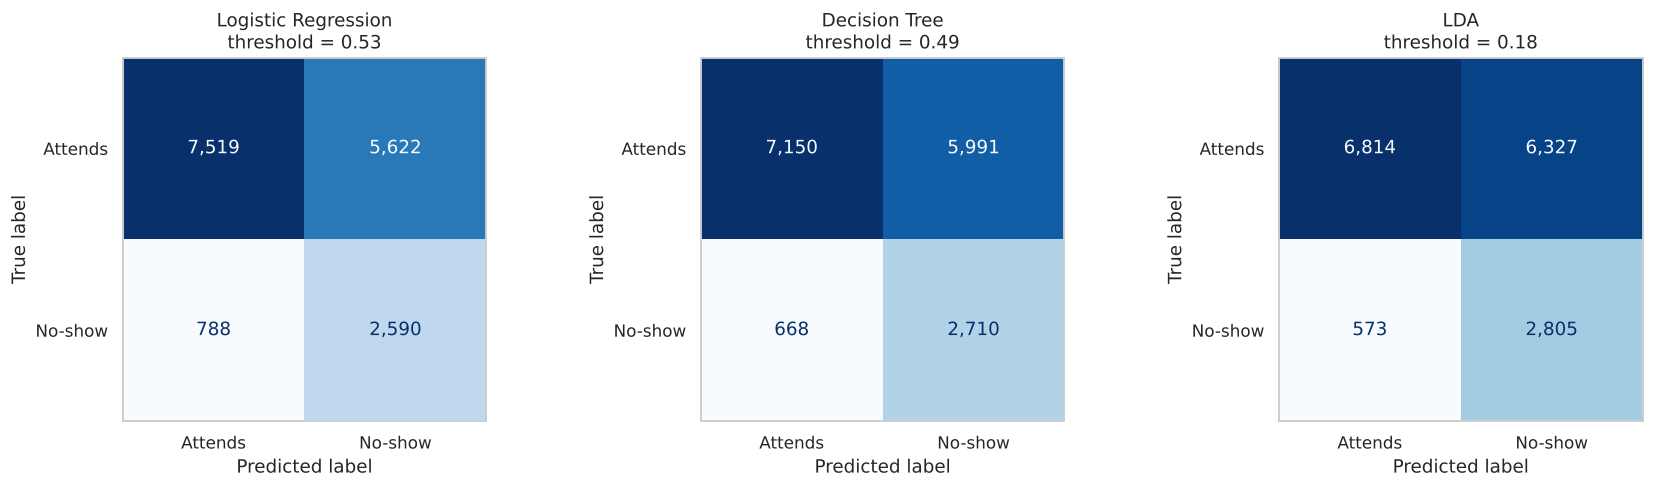

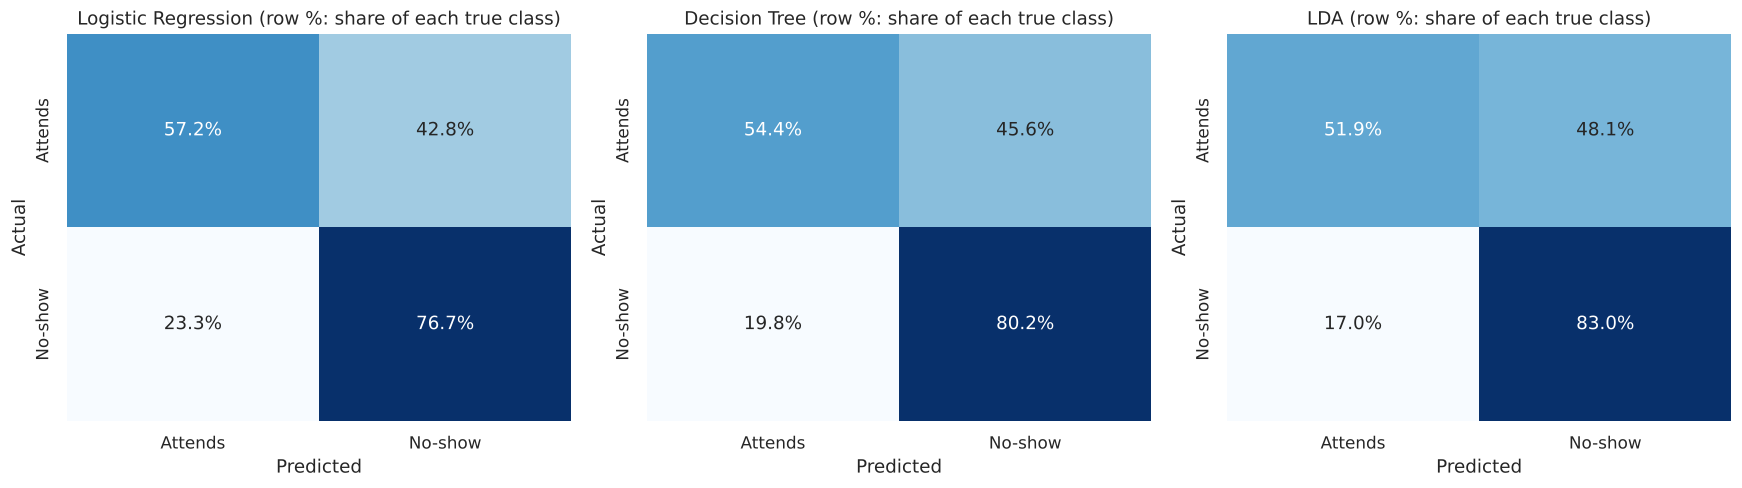

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, name in zip(ax, final_models):
    pred = (test_proba[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Attends", "No-show"]).plot(
        ax=a, cmap="Blues", colorbar=False, values_format=",")
    a.set_title(f"{name}\nthreshold = {thresholds[name]:.2f}")
    a.grid(False)
save("P01_confusion_matrices")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, name in zip(ax, final_models):
    pred = (test_proba[name] >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Attends", "No-show"], yticklabels=["Attends", "No-show"])
    a.set_title(f"{name} (row %: share of each true class)"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
save("P02_confusion_matrices_normalised")

### ROC and precision-recall curves (test set)

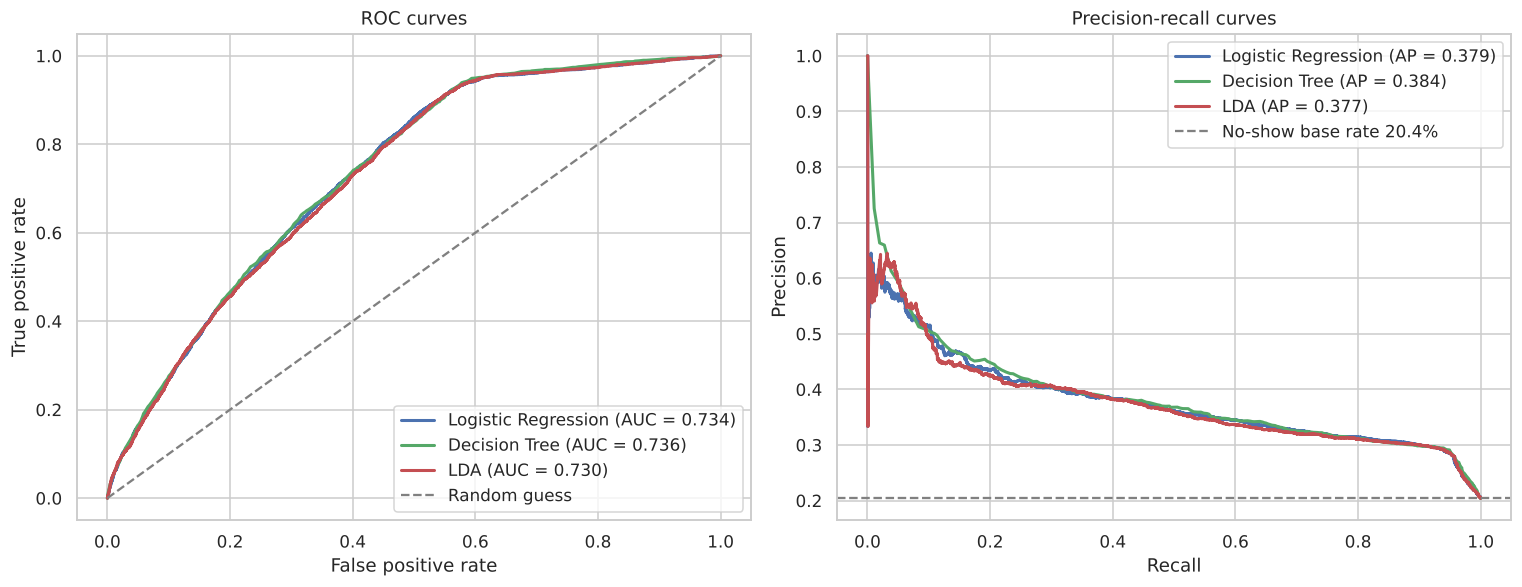

In [ ]:
colors = {"Logistic Regression": "#4c72b0", "Decision Tree": "#55a868", "LDA": "#c44e52"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for name in final_models:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax[0].plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, test_proba[name]):.3f})")
    p, r, _ = precision_recall_curve(y_test, test_proba[name])
    ax[1].plot(r, p, color=colors[name], lw=2, label=f"{name} (AP = {average_precision_score(y_test, test_proba[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
ax[0].set_title("ROC curves"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), ls="--", color="grey", label=f"No-show base rate {y_test.mean():.1%}")
ax[1].set_title("Precision-recall curves"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
save("P03_roc_pr_curves")

### Model comparison

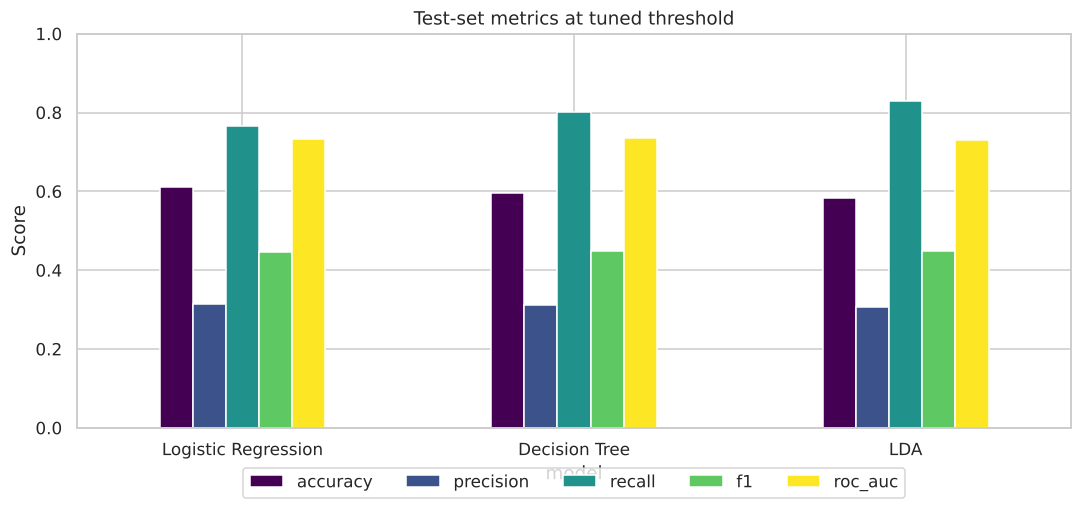

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.612,0.315,0.767,0.447,0.734
Decision Tree,0.597,0.312,0.802,0.449,0.736
LDA,0.582,0.307,0.830,0.448,0.730


In [ ]:
tuned = eval_df[eval_df["threshold_type"] == "tuned"].set_index("model")[["accuracy", "precision", "recall", "f1", "roc_auc"]]
ax = tuned.plot.bar(figsize=(10, 4.8), rot=0, colormap="viridis")
ax.set_ylim(0, 1); ax.set_title("Test-set metrics at tuned threshold"); ax.set_ylabel("Score")
ax.legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, -0.08))
save("P04_model_comparison")
tuned.round(3)

### What drives the predictions?

Left to right: Logistic Regression and LDA coefficients (positive = more likely to be a no-show; numeric features are standardised, so sizes are comparable), and Decision Tree feature importance.

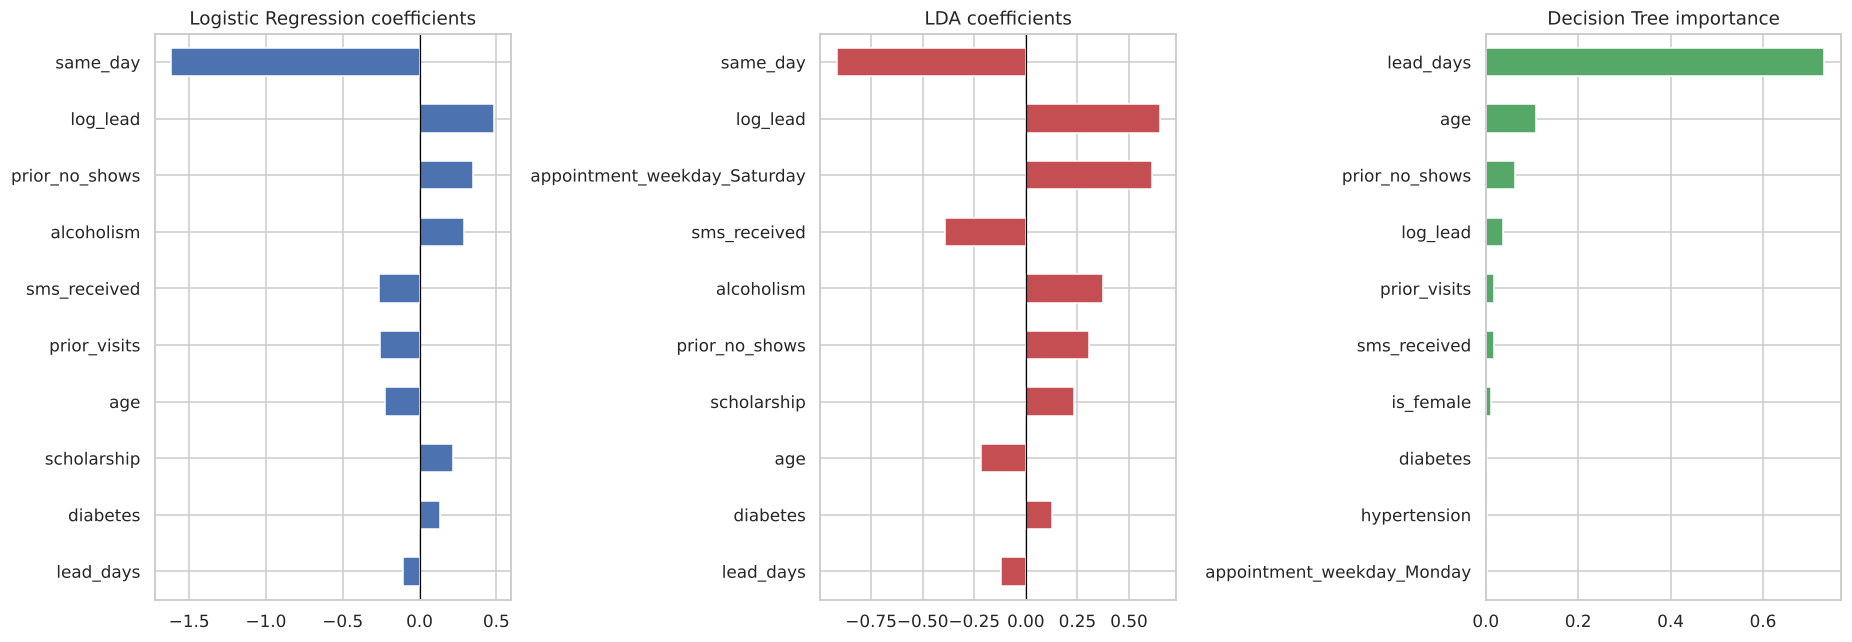

,logreg_coef,odds_ratio
log_lead,0.487,1.628
prior_no_shows,0.348,1.416
alcoholism,0.291,1.338
scholarship,0.217,1.242
diabetes,0.130,1.139
appointment_weekday_Friday,0.101,1.107
appointment_weekday_Tuesday,0.062,1.064
appointment_weekday_Monday,0.059,1.060


In [ ]:
names = final_models["Logistic Regression"].named_steps["prep"].get_feature_names_out()
names = [n.split("__")[1] for n in names]
lr_coef = pd.Series(final_models["Logistic Regression"].named_steps["clf"].coef_[0], index=names)
lda_coef = pd.Series(final_models["LDA"].named_steps["clf"].coef_[0], index=names)
dt_imp = pd.Series(final_models["Decision Tree"].named_steps["clf"].feature_importances_, index=names)

fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a, s, title, col in [(ax[0], lr_coef, "Logistic Regression coefficients", "#4c72b0"),
                         (ax[1], lda_coef, "LDA coefficients", "#c44e52"),
                         (ax[2], dt_imp, "Decision Tree importance", "#55a868")]:
    top = s.reindex(s.abs().sort_values(ascending=False).index[:10]).iloc[::-1]
    top.plot.barh(ax=a, color=col); a.set_title(title)
    if title != "Decision Tree importance": a.axvline(0, color="black", lw=.8)
save("P05_feature_effects")

pd.DataFrame({"logreg_coef": lr_coef, "lda_coef": lda_coef, "tree_importance": dt_imp}).round(4).sort_values(
    "tree_importance", ascending=False).to_csv("results/predictive_feature_effects.csv")
pd.DataFrame({"logreg_coef": lr_coef, "odds_ratio": np.exp(lr_coef)}).round(3).sort_values("logreg_coef", ascending=False).head(8)

### The decision tree as rules

The tree chosen above may be deep, so for reading we draw a small illustrative tree (depth 3) fitted on the same training data.

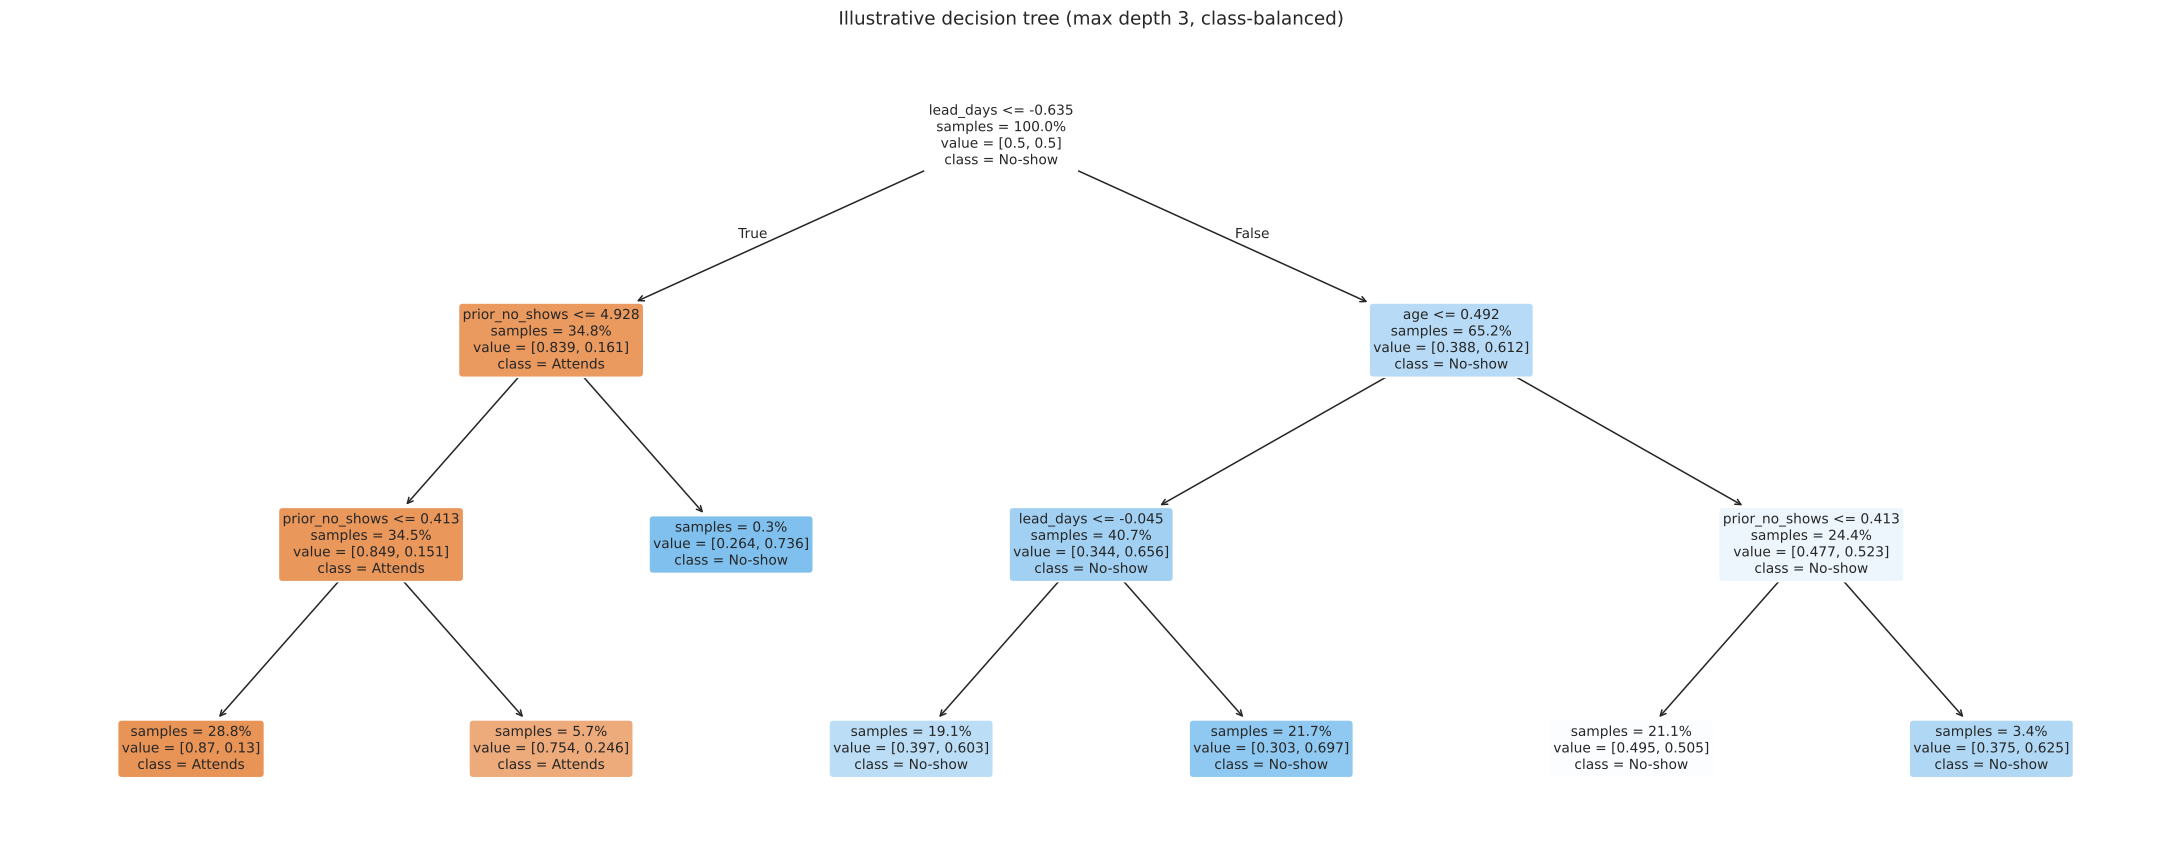

In [ ]:
show_pipe = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, class_weight="balanced",
                                              random_state=RANDOM_STATE)).fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(show_pipe.named_steps["clf"], feature_names=names, class_names=["Attends", "No-show"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Illustrative decision tree (max depth 3, class-balanced)")
save("P06_decision_tree")

### Does the ranking help the clinic? (lift by risk group)

Test appointments are sorted by predicted risk (Logistic Regression) and split into 5 equal groups. If the model works, the highest-risk group should miss far more often than the lowest.

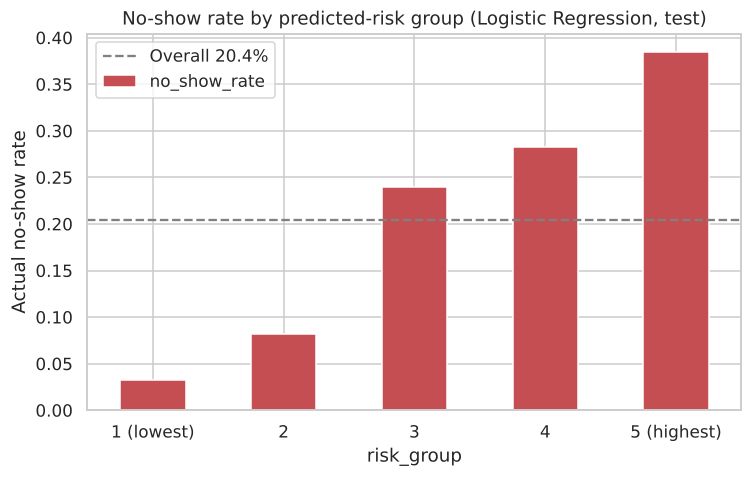

,appointments,no_show_rate,no_shows,share_of_all_no_shows
risk_group,,,,
1 (lowest),3304,0.0324,107,0.0317
2,3304,0.0820,271,0.0802
3,3303,0.2401,793,0.2348
4,3304,0.2830,935,0.2768
5 (highest),3304,0.3850,1272,0.3766


In [ ]:
lift = pd.DataFrame({"risk": test_proba["Logistic Regression"], "no_show": y_test.values})
lift["risk_group"] = pd.qcut(lift["risk"].rank(method="first"), 5, labels=["1 (lowest)", "2", "3", "4", "5 (highest)"])
lift_tbl = lift.groupby("risk_group", observed=True).agg(appointments=("no_show", "size"), no_show_rate=("no_show", "mean"),
                                                         no_shows=("no_show", "sum")).round(4)
lift_tbl["share_of_all_no_shows"] = (lift_tbl["no_shows"] / lift_tbl["no_shows"].sum()).round(4)
lift_tbl.to_csv("results/predictive_risk_groups.csv")

ax = lift_tbl["no_show_rate"].plot.bar(figsize=(7, 4.5), color="#c44e52", rot=0)
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Overall {y_test.mean():.1%}")
ax.set_title("No-show rate by predicted-risk group (Logistic Regression, test)"); ax.set_ylabel("Actual no-show rate"); ax.legend()
save("P07_risk_groups")
lift_tbl

## 7. Export predictions, experiment log and model artifacts

In [ ]:
pred_df = df.iloc[test_idx][["appointment_id", "patient_id", "age", "lead_days", "sms_received", "no_show", TARGET]].copy()
pred_df = pred_df.rename(columns={TARGET: "actual_no_show"})
for name, tag in [("Logistic Regression", "logreg"), ("Decision Tree", "tree"), ("LDA", "lda")]:
    pred_df[f"{tag}_probability"] = test_proba[name].round(4)
    pred_df[f"{tag}_pred_default"] = (test_proba[name] >= 0.5).astype(int)
    pred_df[f"{tag}_pred_tuned"] = (test_proba[name] >= thresholds[name]).astype(int)
pred_df.sort_values("appointment_id").to_csv("results/predictive_predictions.csv", index=False)

log_df = pd.DataFrame(experiment_log)
log_df.insert(0, "experiment_id", range(1, len(log_df) + 1))
log_df.to_csv("results/model_experiment_log.csv", index=False)
with pd.ExcelWriter("results/model_experiment_log.xlsx") as xw:
    log_df.to_excel(xw, sheet_name="Experiment log", index=False)
    eval_df.to_excel(xw, sheet_name="Final test results", index=False)
    pd.DataFrame([{"model": k, "chosen_settings": v, "threshold": round(thresholds[k], 3)} for k, v in chosen.items()]
                 ).to_excel(xw, sheet_name="Chosen settings", index=False)

joblib.dump({"models": final_models, "thresholds": thresholds, "features": FEATURES, "chosen_settings": chosen,
             "random_state": RANDOM_STATE}, "model_artifacts.pkl")

print("results/:", sorted(os.listdir("results")))
print("figures/:", sorted(os.listdir("figures")))
print("experiments logged:", len(log_df))
log_df.tail(12)

results/: ['model_experiment_log.csv', 'model_experiment_log.xlsx', 'predictive_evaluation.csv', 'predictive_feature_effects.csv', 'predictive_predictions.csv', 'predictive_risk_groups.csv']
figures/: ['P01_confusion_matrices.png', 'P02_confusion_matrices_normalised.png', 'P03_roc_pr_curves.png', 'P04_model_comparison.png', 'P05_feature_effects.png', 'P06_decision_tree.png', 'P07_risk_groups.png']
experiments logged: 55


,experiment_id,model,run,hyperparameters,train_rows,eval_set,threshold,accuracy,precision,recall,f1,roc_auc,avg_precision,notes
43,44,Logistic Regression,"SELECTED (validation, tuned threshold)","C=0.1, class_weight=balanced",77219,validation,0.53,0.6204,0.3148,0.7569,0.4447,0.7341,0.3809,Best validation ROC-AUC; threshold maximises v...
44,45,Decision Tree,"SELECTED (validation, tuned threshold)","max_depth=None, min_samples_leaf=200, class_we...",77219,validation,0.49,0.6025,0.3094,0.7952,0.4455,0.7337,0.3779,Best validation ROC-AUC; threshold maximises v...
45,46,LDA,"SELECTED (validation, tuned threshold)","lsqr, shrinkage=auto",77219,validation,0.18,0.5865,0.3043,0.8231,0.4443,0.7325,0.3806,Best validation ROC-AUC; threshold maximises v...
46,47,Logistic Regression,5-fold grouped CV (train),"C=0.1, class_weight=balanced",77219,train CV,NaN,NaN,NaN,NaN,NaN,0.7358,NaN,ROC-AUC std across folds = 0.0057
47,48,Decision Tree,5-fold grouped CV (train),"max_depth=None, min_samples_leaf=200, class_we...",77219,train CV,NaN,NaN,NaN,NaN,NaN,0.7340,NaN,ROC-AUC std across folds = 0.0038
48,49,LDA,5-fold grouped CV (train),"lsqr, shrinkage=auto",77219,train CV,NaN,NaN,NaN,NaN,NaN,0.7337,NaN,ROC-AUC std across folds = 0.0061
49,50,Logistic Regression,FINAL TEST (default 0.5),"C=0.1, class_weight=balanced",77219,test,0.50,0.5861,0.3089,0.8280,0.4500,0.7335,0.3785,"Held-out patients, used once"
50,51,Logistic Regression,FINAL TEST (tuned),"C=0.1, class_weight=balanced",77219,test,0.53,0.6120,0.3154,0.7667,0.4469,0.7335,0.3785,"Held-out patients, used once"
51,52,Decision Tree,FINAL TEST (default 0.5),"max_depth=None, min_samples_leaf=200, class_we...",77219,test,0.50,0.5988,0.3118,0.7969,0.4482,0.7361,0.3837,"Held-out patients, used once"
52,53,Decision Tree,FINAL TEST (tuned),"max_depth=None, min_samples_leaf=200, class_we...",77219,test,0.49,0.5969,0.3115,0.8022,0.4487,0.7361,0.3837,"Held-out patients, used once"


In [ ]:
# Optional (Colab): bundle everything into one zip and download it
import shutil
shutil.make_archive("predictive_outputs", "zip", ".", "results")
try:
    from google.colab import files
    shutil.make_archive("predictive_figures", "zip", ".", "figures")
    files.download("predictive_outputs.zip"); files.download("predictive_figures.zip"); files.download("model_artifacts.pkl")
except ImportError:
    pass

## Summary of findings

| Model | Chosen setting | Test ROC-AUC | Recall (no-show) | Precision | F1 | Accuracy |
|---|---|---|---|---|---|---|
| Logistic Regression | C=0.1, class_weight=balanced, threshold 0.53 | 0.734 | 76.7% | 31.5% | 0.447 | 61.2% |
| Decision Tree | min_samples_leaf=200, class_weight=balanced, threshold 0.49 | 0.736 | 80.2% | 31.2% | 0.449 | 59.7% |
| LDA | lsqr, shrinkage=auto, threshold 0.18 | 0.731 | 83.0% | 30.7% | 0.448 | 58.2% |
| Baseline (always attends) | - | 0.500 | 0% | - | 0 | 79.6% |

- **All three models perform about the same** (test ROC-AUC 0.73 to 0.74, cross-validation spread under 0.007). The booking-time information limits how well any of them can do; choosing a different algorithm changes little.
- **The models rank risk well, but cannot label individual no-shows precisely.** About 3 in 10 appointments flagged as no-show really are (base rate is 20.4%), while 77% to 83% of real no-shows are caught. Accuracy is *lower* than the baseline's 79.6% because the models deliberately flag many appointments; accuracy is not the right measure here.
- **Risk groups are useful:** the highest-risk 20% of appointments (Logistic Regression) miss 38.5% of the time versus 3.2% in the lowest 20%, and the top 40% contains about 65% of all no-shows.
- **Main drivers:** lead time (same-day bookings almost never miss; long waits miss more; 73% of the tree's importance), a previous no-show, and younger age. An SMS reminder is linked to *fewer* no-shows once lead time is accounted for, matching the descriptive result.
- **Default threshold warning:** LDA at 0.5 flags almost nothing (recall 3.7%). Threshold tuning on validation data fixes this and should be reported.

**Limitations:** 0/1 flags do not satisfy the normality assumption of LDA; the dataset has no information on reasons for missing (transport, weather, illness); neighbourhood was not used; one random patient-level split was used for the final test (cross-validation on the training patients confirms stability).